# 04 · Verification

**Question:** do the findings of `03_event_effect` survive other reasonable choices?

The main model from notebook 03 (Step 3: day of week × hour, plus the untimed-event-day control) is re-run under different choices, and the event effects are compared. A result that moves a lot with a small change is not trustworthy;
a result that stays put is.

| Check | What changes |
|---|---|
| 1. Main model | Rebuilt from scratch here; must match notebook 03 |
| 2. Event windows | 1 or 3 hours before and after the event; games of 2 or 4 hours instead of 3 |
| 3. Model choices | the earlier weekday/weekend × hour grouping, only day of week × hour, month × year, a different distribution, no untimed-event-day control, no controls |
| 4. Which hours are used | without winter, January 2025, holidays, snow, multi-event days, CNE / TIFF / marathon days; each year; weekdays or weekends only |
| 5. Fake events | all events moved to random days with no event (and not on CNE, TIFF or marathon days), 200 times, and the model refitted |
| 6. Summary | what holds, what does not |

Rate ratios read as before: 1.00 = no difference, 1.10 = 10% more incidents, 0.90 = 10% fewer.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Works whether the kernel starts in notebooks/ or in the project root
PROCESSED = next(p for p in (Path("../data/processed"), Path("data/processed")) if p.exists())

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)

GROUP_OF_TYPE = {"mlb": "mlb", "nhl": "nhl", "nba": "nba", "mls": "mls", "world_cup": "other", "parade": "other", "festival": "other", "road_race": "other"}
EVENT_FLAGS = {"win_mlb": "Baseball", "win_nhl": "Hockey", "win_nba": "Basketball", "win_mls": "Toronto FC", "win_other": "Other events"}
GROUP_COLORS = {"Baseball": "#2e86c1", "Hockey": "#1f3a5f", "Basketball": "#c0392b", "Toronto FC": "#6aa84f", "Other events": "#8e7cc3"}
CODING_CHANGE = pd.Timestamp("2026-04-01")

events = pd.read_csv(PROCESSED / "events.csv", parse_dates=["date", "start", "end", "window_start", "window_end"])
hourly = pd.read_csv(PROCESSED / "hourly.csv", parse_dates=["datetime", "date"])
daily = pd.read_csv(PROCESSED / "daily.csv", parse_dates=["date"])
incidents = pd.read_csv(PROCESSED / "incidents.csv", parse_dates=["datetime"], usecols=["datetime", "min_delay"])
timed = events.dropna(subset=["start"]).drop_duplicates("event_id").copy()
timed["group"] = timed["event_type"].map(GROUP_OF_TYPE)
print(f"{len(timed)} events with a start time | {len(hourly):,} hours")

353 events with a start time | 15,312 hours


## 1. The model table, with adjustable event windows

`build_table` rebuilds the modelling table of notebook 03 (Step 1) for any window rule:
`before` and `after` are the hours added before the start and after the end, and `game_hours` is the assumed length of games with no end time. The default is 2, 2 and 3, as in notebook 03.

In [2]:
long_delays = (incidents["min_delay"] > 30).groupby(incidents["datetime"].dt.floor("h")).sum()
BASE = hourly[["datetime", "date", "hour", "weekday", "is_weekend", "month", "year", "n_incidents", "n_diversion", "delay_min_total"]].rename(columns={"delay_min_total": "delay_minutes"})
BASE["n_long_delays"] = BASE["datetime"].map(long_delays).fillna(0).astype(int)
day_ctrl = daily[["date", "is_holiday", "temp_mean_c", "rain_mm", "snow_cm", "snow_3d_cm", "n_events"]]
BASE = BASE.merge(day_ctrl, on="date", how="left", validate="many_to_one")
BASE["is_holiday"] = BASE["is_holiday"].astype(int)
BASE["multi_event_day"] = (BASE["n_events"] >= 2).astype(int)
# Events with no start time (CNE, TIFF, the marathon) have no hourly window. Their days get their own control, as in notebook 03.
BASE["untimed_event_day"] = BASE["date"].isin(set(events.loc[events["window_start"].isna(), "date"])).astype(int)
BASE["heavy_rain"] = (BASE["rain_mm"] >= 10).astype(int)
BASE["snow_day"] = (BASE["snow_cm"] > 0).astype(int)
BASE["snow3_over5"] = (BASE["snow_3d_cm"] > 5).astype(int)
BASE["snowy"] = BASE["snow_3d_cm"] > 2
BASE["temp_band"] = pd.cut(BASE["temp_mean_c"], [-40, -10, 0, 10, 20, 25, 40], labels=["below -10", "-10 to 0", "0 to 10", "10 to 20", "20 to 25", "above 25"]).astype(str)
BASE["weekday_type"] = np.where(BASE["is_weekend"], "weekend", "weekday")
BASE["slot"] = BASE["weekday_type"] + "_" + BASE["hour"].astype(str)
BASE["weekday_slot"] = BASE["weekday"] + "_" + BASE["hour"].astype(str)
BASE["period"] = BASE["date"].dt.to_period("M").astype(str)
BASE["after_coding_change"] = (BASE["date"] >= CODING_CHANGE).astype(int)
BASE["evening_date"] = (BASE["datetime"] - pd.Timedelta(hours=6)).dt.normalize()
BASE["in_scope"] = (BASE["hour"] >= 11) | (BASE["hour"] == 0)


def window_hours(before=2, after=2, game_hours=3):
    """One row per event-hour: (event_id, group, datetime, offset from the start hour)."""
    rows = []
    for r in timed.itertuples():
        end = r.end if pd.notna(r.end) else r.start + pd.Timedelta(hours=game_hours)
        for hour in pd.date_range((r.start - pd.Timedelta(hours=before)).floor("h"), end + pd.Timedelta(hours=after), freq="h", inclusive="left"):
            rows.append((r.event_id, r.group, hour, int((hour - r.start.floor("h")) / pd.Timedelta(hours=1))))
    return pd.DataFrame(rows, columns=["event_id", "group", "datetime", "offset"])


def build_table(before=2, after=2, game_hours=3):
    wh = window_hours(before, after, game_hours)
    flags = pd.crosstab(wh["datetime"], wh["group"]).gt(0).astype(int).add_prefix("win_").reset_index()
    table = BASE.merge(flags, on="datetime", how="left")
    for col in EVENT_FLAGS:
        table[col] = table.get(col, 0)
        table[col] = table[col].fillna(0).astype(int)
    table["in_event_window"] = (table[list(EVENT_FLAGS)].sum(axis=1) > 0).astype(int)
    return table[table["in_scope"]].reset_index(drop=True)


main_table = build_table()
print(f"{len(main_table):,} hours | event-window hours: {int(main_table['in_event_window'].sum()):,} | by group: "
      f"{ {EVENT_FLAGS[c]: int(main_table[c].sum()) for c in EVENT_FLAGS} }")

8,932 hours | event-window hours: 2,519 | by group: {'Baseball': 1366, 'Hockey': 506, 'Basketball': 525, 'Toronto FC': 239, 'Other events': 93}


### 1.1 Model functions and the main model (must match notebook 03)

In [3]:
EVENTS_RHS = " + ".join(EVENT_FLAGS)
TEMP = "C(temp_band, Treatment('10 to 20'))"
RHS_MAIN = f"C(weekday_slot) + C(month) + is_holiday + snow_day + snow3_over5 + {TEMP} + heavy_rain + after_coding_change + multi_event_day + untimed_event_day"


def drop_constant_terms(data, rhs):
    """Remove yes/no controls that never vary in a subset (they cannot be estimated)."""
    for term in ["is_holiday", "snow_day", "snow3_over5", "heavy_rain", "after_coding_change", "multi_event_day", "untimed_event_day"]:
        if data[term].nunique() < 2:
            rhs = rhs.replace(f" + {term}", "")
    return rhs


def fit_model(data, rhs=RHS_MAIN, outcome="n_incidents", family="poisson"):
    """Poisson (or negative binomial) regression with standard errors clustered by evening."""
    rhs = drop_constant_terms(data, rhs)
    groups = pd.factorize(data["evening_date"])[0]
    fam = sm.families.Poisson()
    if family == "negbin":
        first = smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=data, family=sm.families.Poisson()).fit()
        mu = first.fittedvalues
        alpha = max(float((((data[outcome] - mu) ** 2 - mu) / mu ** 2).mean()), 1e-3)
        fam = sm.families.NegativeBinomial(alpha=alpha)
    return smf.glm(f"{outcome} ~ {EVENTS_RHS} + {rhs}", data=data, family=fam).fit(cov_type="cluster", cov_kwds={"groups": groups})


def event_effects(res):
    ci = res.conf_int()
    t = pd.DataFrame({"rate_ratio": np.exp(res.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1])}).loc[list(EVENT_FLAGS)]
    return t.rename(index=EVENT_FLAGS)


main_effects = event_effects(fit_model(main_table))
main_effects.round(3)

,rate_ratio,lo,hi
Baseball,1.030,0.983,1.080
Hockey,0.970,0.889,1.058
Basketball,0.930,0.858,1.007
Toronto FC,0.985,0.905,1.073
Other events,0.944,0.845,1.055


**Check against notebook 03:** the rate ratios above should equal the main model there
(baseball 1.030, hockey 0.970, basketball 0.930, Toronto FC 0.985, other events 0.944).

In [4]:
expected_main = {"Baseball": 1.030, "Hockey": 0.970, "Basketball": 0.930, "Toronto FC": 0.985, "Other events": 0.944}
assert all(abs(main_effects.loc[k, "rate_ratio"] - v) < 0.002 for k, v in expected_main.items()), "does not match notebook 03"
print("The rebuilt main model matches notebook 03")

The rebuilt main model matches notebook 03


## 2. Different event windows
The window is a choice. Here the hours added before the start and after the end are changed (1, 2 or 3), and games are assumed to last 2, 3 or 4 hours.

,Baseball,Hockey,Basketball,Toronto FC,Other events
main,1.030,0.970,0.930,0.985,0.944
"window: 1 h before, 1 h after",1.027,0.972,0.916,0.959,0.946
"window: 3 h before, 3 h after",1.022,0.968,0.950,0.995,0.976
"window: 0 h before, 0 h after (game only)",1.043,0.963,0.902,0.917,0.929
games last 2 hours,1.020,0.964,0.918,0.982,0.956
games last 4 hours,1.035,0.967,0.932,0.996,0.946


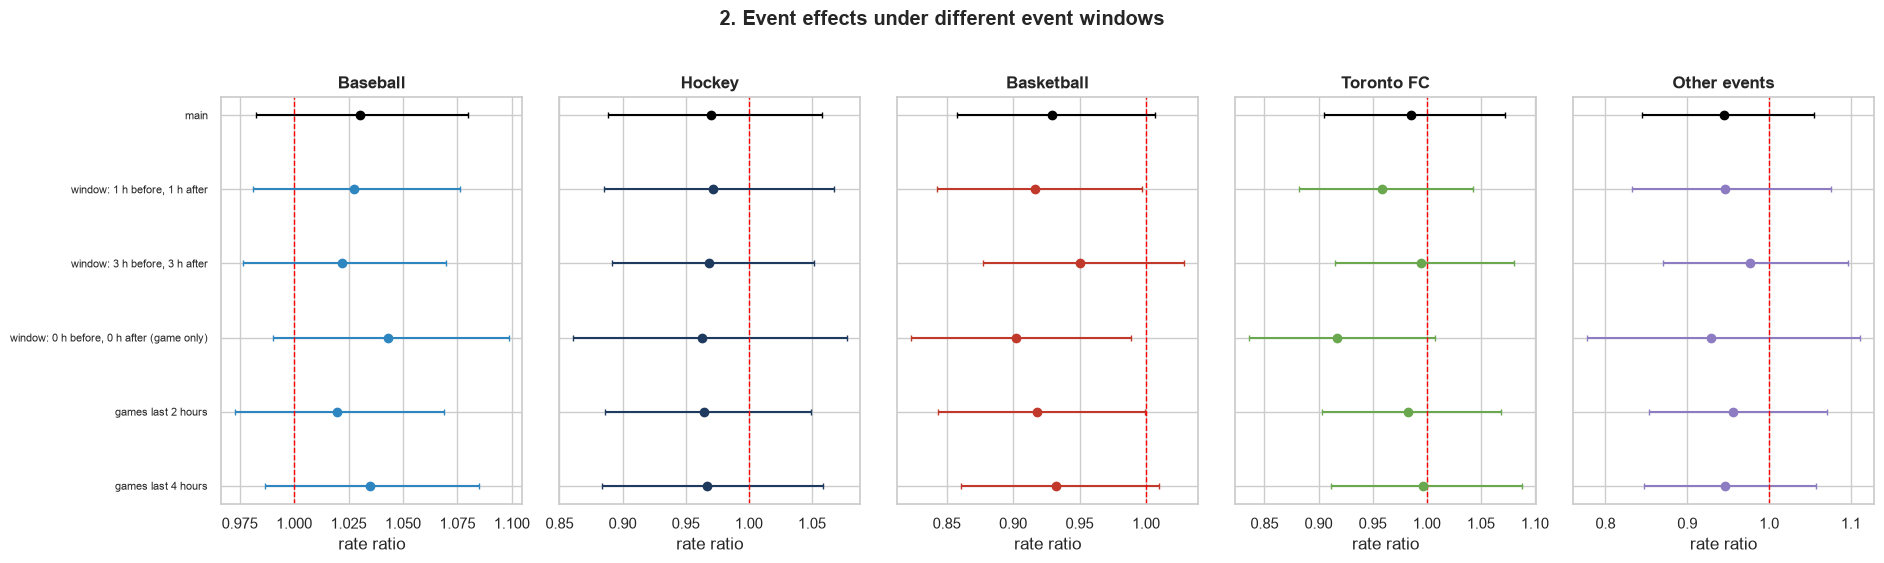

In [5]:
RESULTS = {"main": main_effects}   # collected for the summary in section 6
window_variants = {
    "window: 1 h before, 1 h after": dict(before=1, after=1),
    "window: 3 h before, 3 h after": dict(before=3, after=3),
    "window: 0 h before, 0 h after (game only)": dict(before=0, after=0),
    "games last 2 hours": dict(game_hours=2),
    "games last 4 hours": dict(game_hours=4),
}
for name, kwargs in window_variants.items():
    RESULTS[name] = event_effects(fit_model(build_table(**kwargs)))
window_table = pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in ["main"] + list(window_variants)}).T


def plot_checks(names, title):
    """One panel per event group: the rate ratio and interval under each check."""
    fig, axes = plt.subplots(1, 5, figsize=(19, 0.55 * len(names) + 2.2), sharey=True)
    ypos = np.arange(len(names))[::-1]
    for ax, group in zip(axes, EVENT_FLAGS.values()):
        for yi, name in zip(ypos, names):
            row = RESULTS[name].loc[group]
            ax.errorbar(row["rate_ratio"], yi, xerr=[[row["rate_ratio"] - row["lo"]], [row["hi"] - row["rate_ratio"]]], fmt="o", color=GROUP_COLORS[group] if name != "main" else "black", capsize=2)
        ax.axvline(1, color="red", ls="--", lw=1)
        ax.set(title=group, xlabel="rate ratio")
    axes[0].set_yticks(ypos)
    axes[0].set_yticklabels(names, fontsize=8)
    fig.suptitle(title, fontweight="bold", y=1.02)
    plt.tight_layout()


plot_checks(["main"] + list(window_variants), "2. Event effects under different event windows")
window_table.round(3)

**How to read it:** each row re-fits the main model with another event window. The plot shows the rate ratio and interval for each event type; the black dot is the main model.

**What stands out:**
- **Basketball stays between 0.90 and 0.95** whatever the window (1, 2 or 3 hours around the game, games of 2, 3 or 4 hours). The interval excludes 1 in three of the five versions (1 hour around the game, the game only, games of 2 hours) and not in the others, like the main model (0.93).
- **Baseball stays between 1.02 and 1.04, hockey between 0.96 and 0.97, other events between 0.93 and 0.98.** None are clear in any version.
- **Toronto FC is between 0.92 and 1.00**, lowest (0.92) when only the game itself is counted. It is not clear in any version.

**What it means:** the window is not what drives the results.

## 3. Different model choices
The earlier grouping (weekday/weekend × hour, 28 groups) instead of day of week × hour (98 groups); only day of week × hour with no other controls; month × year instead of calendar month; the model without the untimed-event-day control; a negative binomial distribution instead of Poisson; and the extreme of no controls at all.

,Baseball,Hockey,Basketball,Toronto FC,Other events
main,1.030,0.970,0.930,0.985,0.944
"weekday/weekend x hour (28 groups, earlier main)",1.038,0.969,0.914,1.095,0.978
month x year (21 periods),1.033,0.976,0.930,0.978,0.978
only day of week x hour,0.995,0.974,0.907,0.974,0.946
no untimed-event-day control,1.024,0.965,0.927,0.978,0.922
no controls,0.965,0.877,0.791,0.991,1.003
negative binomial,1.028,0.966,0.929,0.976,0.957


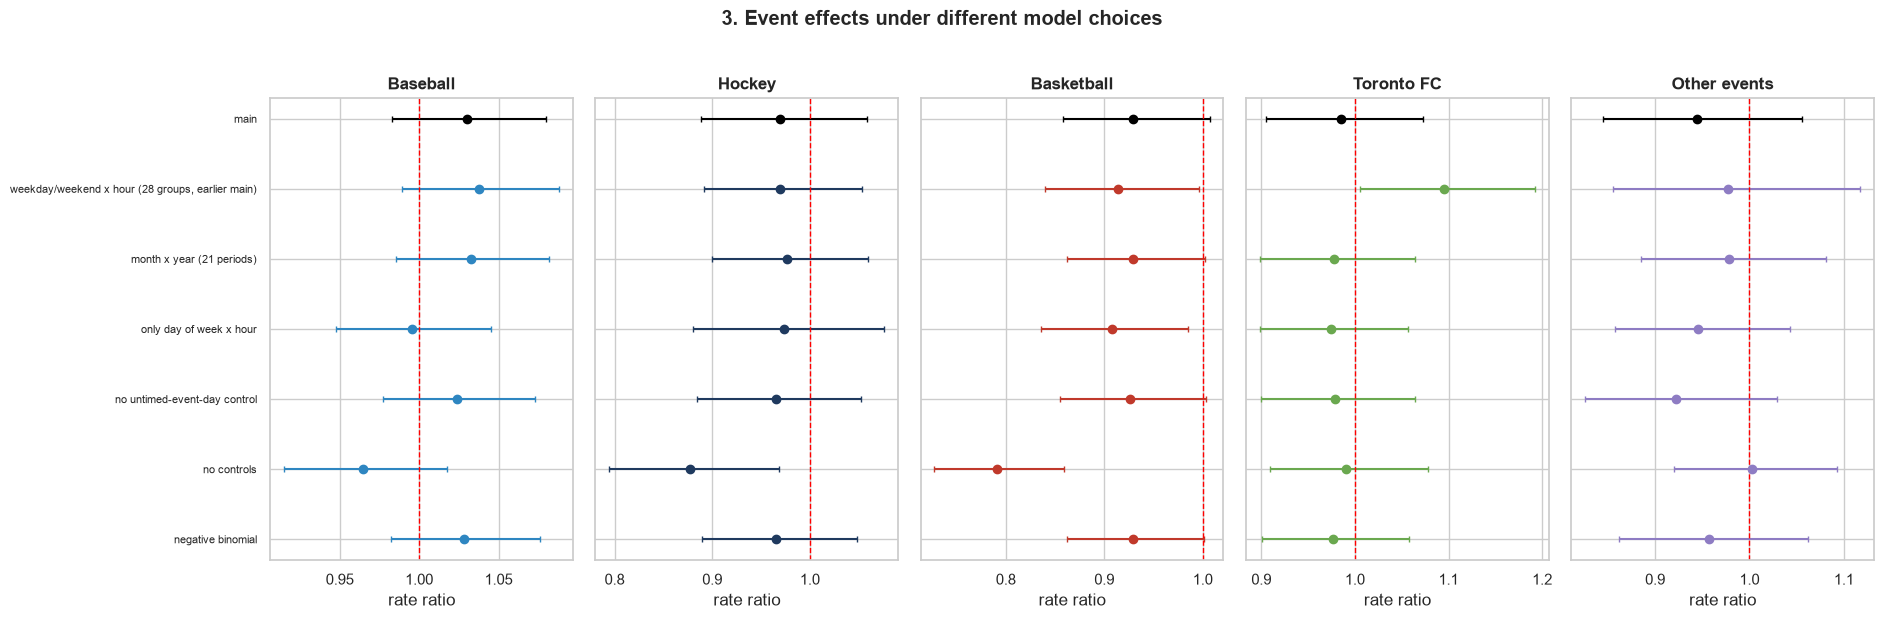

In [6]:
model_variants = {
    "weekday/weekend x hour (28 groups, earlier main)": RHS_MAIN.replace("C(weekday_slot)", "C(slot)"),
    "month x year (21 periods)": RHS_MAIN.replace("C(month)", "C(period)").replace(" + after_coding_change", ""),  # the period already holds the coding change
    "only day of week x hour": "C(weekday_slot)",
    "no untimed-event-day control": RHS_MAIN.replace(" + untimed_event_day", ""),
    "no controls": "1",
}
for name, rhs in model_variants.items():
    RESULTS[name] = event_effects(fit_model(main_table, rhs))
RESULTS["negative binomial"] = event_effects(fit_model(main_table, family="negbin"))
model_names = ["main"] + list(model_variants) + ["negative binomial"]
plot_checks(model_names, "3. Event effects under different model choices")
pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in model_names}).T.round(3)

**How to read it:** the main model with different model choices. The last plot shows each event type under each choice.

**What stands out:**
- **Basketball: 0.91 to 0.93 under every choice that has controls**, and 0.79 with no controls at all. It is clear in two of them (the earlier 28-group grouping, 0.91, and day of week × hour alone, 0.91) and not clear in the others, like the main model.
- **Baseball (0.99 to 1.04), hockey (0.97 to 0.98) and other events (0.92 to 0.98) do not change** between choices.
- **Toronto FC is 1.10 with the earlier weekday/weekend grouping but 0.97 to 0.99 under every other choice.** Toronto FC plays almost only on weekends, so how Saturday is compared with Sunday decided its answer. With day of week × hour it is gone.
- **Leaving out the untimed-event-day control moves the estimates by about 0.02 at most** (other events 0.92 instead of 0.94). Those days run about 8% higher (notebook 03), so the control matters little here, but it is the more correct comparison.
- Without any controls, hockey (0.88) and basketball (0.79) look clearly lower, which shows that the controls matter: they remove part of the apparent dip.
- A negative binomial model, which allows more variation, gives the same answers.

**What it means:** the results do not depend on the distribution or on the controls. The one choice that mattered was how weekends are grouped, and it only mattered for Toronto FC.

## 4. Which hours are used
Dropping groups of hours that could drive the result. The model is refitted on the remaining hours.

rate ratio                                           event hours left                                          
                                           Baseball Hockey Basketball Toronto FC Other events         Baseball Hockey Basketball Toronto FC Other events
main                                          1.030  0.970      0.930      0.985        0.944             1366    506        525        239           93
without Dec to Feb                            1.015  0.959      0.870      0.955        0.933             1366    318        236        239           93
without January 2025                          1.031  0.986      0.913      0.984        0.943             1366    448        462        239           93
without public holidays                       1.038  0.977      0.934      0.986        0.942             1332    491        517        239           93
without recent snow (3-day snow <= 2 cm)      1.021  0.955      0.908      0.969        0.939             1357    383        367        224           93
without multi-event days                      1.035  0.966      0.923      1.015        1.068              874    408        461        119           28
without CNE / TIFF / marathon days            1.041  0.972      0.932      0.984        0.936             1144    499        525        199           93
2025 only                                     1.040  0.938      0.912      0.919        1.028              720    373        327        135           33
2026 only                                     1.023  1.051      0.922      1.033        0.919              646    133        198        104           60
weekdays only                                 1.016  0.929      0.939      0.994        0.888              866    351        381         48           35
weekends only                                 1.048  1.066      0.880      1.000        0.971              500    155        144        191           58
17:00 to 23:59 only                           0.986  0.969      0.960      0.976        1.009              913    473        441        146           53

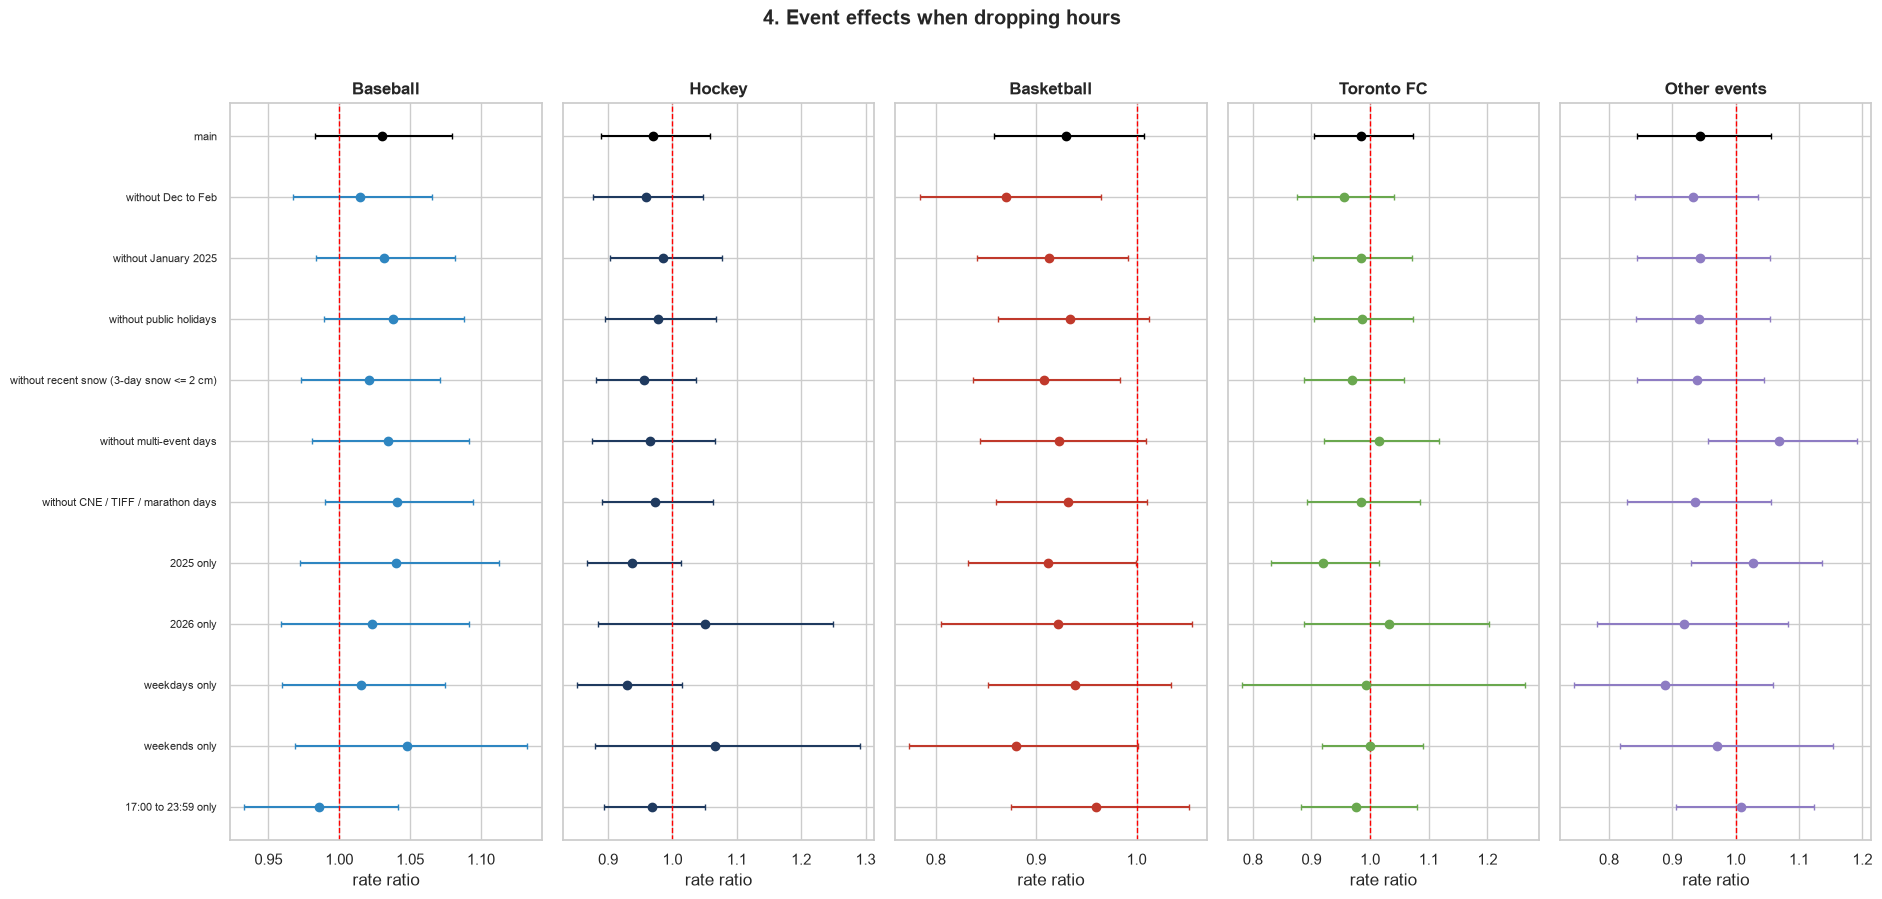

In [7]:
t = main_table
subsets = {
    "without Dec to Feb": ~t["month"].isin([12, 1, 2]),
    "without January 2025": ~((t["year"] == 2025) & (t["month"] == 1)),
    "without public holidays": t["is_holiday"] == 0,
    "without recent snow (3-day snow <= 2 cm)": ~t["snowy"],
    "without multi-event days": t["multi_event_day"] == 0,
    "without CNE / TIFF / marathon days": t["untimed_event_day"] == 0,
    "2025 only": t["year"] == 2025,
    "2026 only": t["year"] == 2026,
    "weekdays only": t["weekday_type"] == "weekday",
    "weekends only": t["weekday_type"] == "weekend",
    "17:00 to 23:59 only": t["hour"].between(17, 23),
}
# in 2026 every month from April on is "after the coding change", so the two controls overlap and the coding flag is left out there
rhs_override = {"2026 only": RHS_MAIN.replace(" + after_coding_change", "")}
for name, mask in subsets.items():
    RESULTS[name] = event_effects(fit_model(t[mask], rhs_override.get(name, RHS_MAIN)))
subset_names = ["main"] + list(subsets)
event_hours_left = pd.DataFrame({name: [int(t.loc[mask if name != "main" else slice(None), c].sum()) for c in EVENT_FLAGS] for name, mask in [("main", None)] + list(subsets.items())},
                                index=EVENT_FLAGS.values()).T
plot_checks(subset_names, "4. Event effects when dropping hours")
pd.concat({"rate ratio": pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in subset_names}).T.round(3), "event hours left": event_hours_left}, axis=1)

**How to read it:** each row removes one kind of hour and re-fits the model. The right-hand block shows how many event hours are left.

**What stands out:**
- **Basketball: 0.87 to 0.96** in all eleven versions. It is **stronger without winter (0.87) and on weekends (0.88)**, and weakest from 5 pm only (0.96) and on weekdays (0.94). The interval excludes 1 in four of them (without Dec to Feb, without January 2025, without recent snow, 2025 only). The dip is **not a winter effect.**
- **Baseball: 0.99 to 1.05** in every version, never clear.
- **Hockey is inconsistent**: 0.94 in 2025 and 1.05 in 2026, 0.93 on weekdays and 1.07 on weekends. It has no stable effect.
- **Toronto FC: 0.92 to 1.03**, never clear, and it has few hours in some cases (only 48 on weekdays).
- **Other events:** 0.89 to 1.07 with 28 to 93 hours, no stable direction.
- **Without the CNE, TIFF and marathon days** nothing changes (baseball 1.04, hockey 0.97, basketball 0.93, Toronto FC 0.98, other events 0.94).

**What it means:** dropping winter, January 2025, holidays, snow days, multi-event days or the untimed-event days never creates an increase for any event type.

## 5. Fake events
Every real event is moved to a **random day with no event and the same weekday**, keeping its hours. The model is refitted (200 times) with the fake events. If events did nothing, the real effects should look like the fake ones.

200 refits in 46 s


,real,fake mean,fake 2.5%,fake 97.5%,share of fake as far from 1
group,,,,,
Baseball,1.030,0.994,0.943,1.040,0.245
Hockey,0.970,1.011,0.942,1.080,0.450
Basketball,0.930,0.994,0.920,1.064,0.060
Toronto FC,0.985,0.973,0.867,1.072,0.785
Other events,0.944,0.974,0.825,1.125,0.535


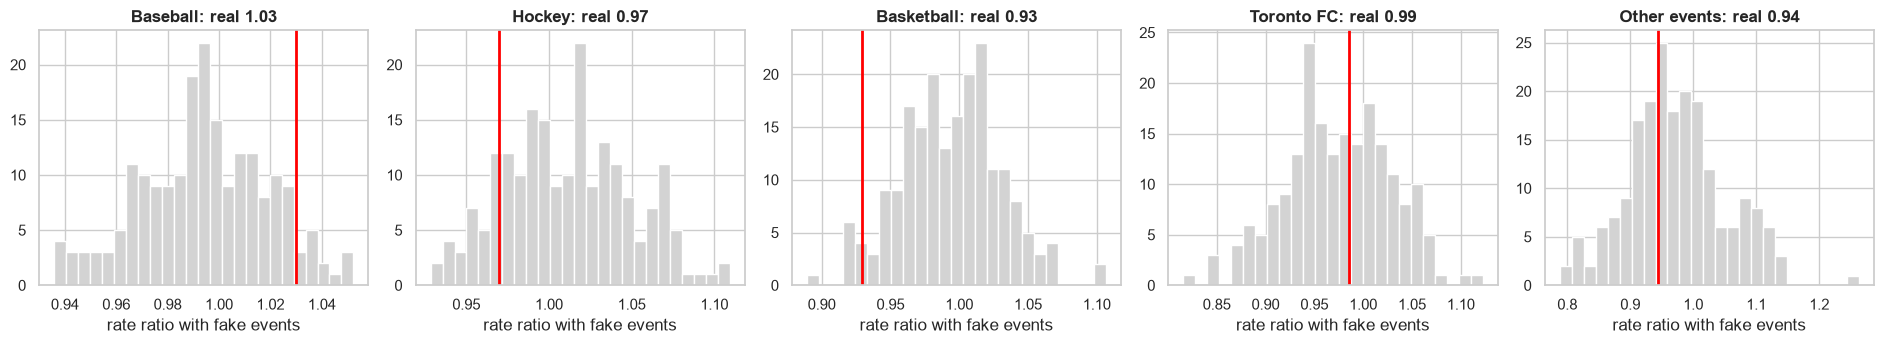

In [8]:
import time

wh = window_hours()
wh = wh.merge(timed[["event_id", "start"]], on="event_id")
wh["base_date"] = wh["start"].dt.normalize()
wh["offset_h"] = ((wh["datetime"] - wh["base_date"]) / pd.Timedelta(hours=1)).astype(int)
event_list = wh.drop_duplicates("event_id")[["event_id", "base_date", "group"]].reset_index(drop=True)
event_list["weekday"] = event_list["base_date"].dt.day_of_week
event_pos = event_list.reset_index().set_index("event_id")["index"]
hour_event = wh["event_id"].map(event_pos).to_numpy()
hour_offset = wh["offset_h"].to_numpy().astype("timedelta64[h]")
hour_group = wh["group"].map(lambda g: f"win_{g}").to_numpy()

times = pd.DatetimeIndex(main_table["datetime"])
real_window = main_table["in_event_window"].to_numpy().astype(bool)
busy_days = set(main_table.loc[(main_table["in_event_window"] == 1) | (main_table["untimed_event_day"] == 1), "evening_date"])   # also not on CNE, TIFF or marathon days
free_days = pd.Series(sorted(set(main_table["evening_date"]) - busy_days))
by_weekday = [free_days[free_days.dt.day_of_week == k].to_numpy() for k in range(7)]
width = max(len(a) for a in by_weekday)
candidates = np.full((7, width), np.datetime64("NaT", "ns"), dtype="datetime64[ns]")
lengths = np.array([len(a) for a in by_weekday])
for k, a in enumerate(by_weekday):
    candidates[k, :len(a)] = a
weekday_codes = event_list["weekday"].to_numpy()


def fake_events_effects(rng):
    pick = (rng.random(len(event_list)) * lengths[weekday_codes]).astype(int)
    target = candidates[weekday_codes, pick][hour_event] + hour_offset
    pos = times.get_indexer(pd.DatetimeIndex(target))
    ok = pos >= 0
    ok[ok] = ~real_window[pos[ok]]
    data = main_table.copy()
    for col in EVENT_FLAGS:
        data[col] = 0
    for col in EVENT_FLAGS:
        sel = ok & (hour_group == col)
        data.loc[data.index[pos[sel]], col] = 1
    return np.exp(fit_model(data).params[list(EVENT_FLAGS)].to_numpy())


rng = np.random.default_rng(5)
start = time.time()
fake_rr = np.array([fake_events_effects(rng) for _ in range(200)])
print(f"200 refits in {time.time() - start:.0f} s")

real_rr = main_effects["rate_ratio"].to_numpy()
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
rows = []
for i, (ax, name) in enumerate(zip(axes, EVENT_FLAGS.values())):
    ax.hist(fake_rr[:, i], bins=25, color="lightgray")
    ax.axvline(real_rr[i], color="red", lw=2)
    ax.set(title=f"{name}: real {real_rr[i]:.2f}", xlabel="rate ratio with fake events")
    rows.append({"group": name, "real": real_rr[i], "fake mean": fake_rr[:, i].mean(), "fake 2.5%": np.percentile(fake_rr[:, i], 2.5),
                 "fake 97.5%": np.percentile(fake_rr[:, i], 97.5), "share of fake as far from 1": (np.abs(np.log(fake_rr[:, i])) >= abs(np.log(real_rr[i]))).mean()})
plt.tight_layout()
placebo = pd.DataFrame(rows).set_index("group")
placebo.round(3)

**How to read it:** the histograms are the effects that **fake events** give: every real event moved to a random day with no event (and not on CNE, TIFF or marathon days) and the same weekday, 200 times, with the full model re-fitted. The red line is the real effect. The table shows the real effect, the fake range, and the share of fake runs as far from 1 as the real one.

**What stands out:**
- **Basketball: real 0.930, fake range 0.920 to 1.064, and 6% of the fake runs are as far from 1.** It is the closest to being different from chance, but it does not clear the usual 5% line.
- **Baseball (25% of fake runs as far from 1), hockey (45%), Toronto FC (79%) and other events (54%) all fall within what chance gives.**
- **Toronto FC's fake events now average 0.97**, not 1.11 as with the earlier weekday/weekend grouping. The earlier rise came from how Saturdays compared with the weekend average; with day of week × hour it is gone.

**What it means:** with the finer grouping, no event type is clearly different from chance. Basketball is the closest (6%).

## 6. Summary of the checks

,lowest,highest,main,checks with interval excluding 1,checks in total
Baseball,0.965,1.048,1.030,0,23
Hockey,0.877,1.066,0.970,1,23
Basketball,0.791,0.960,0.930,10,23
Toronto FC,0.917,1.095,0.985,1,23
Other events,0.888,1.068,0.944,0,23


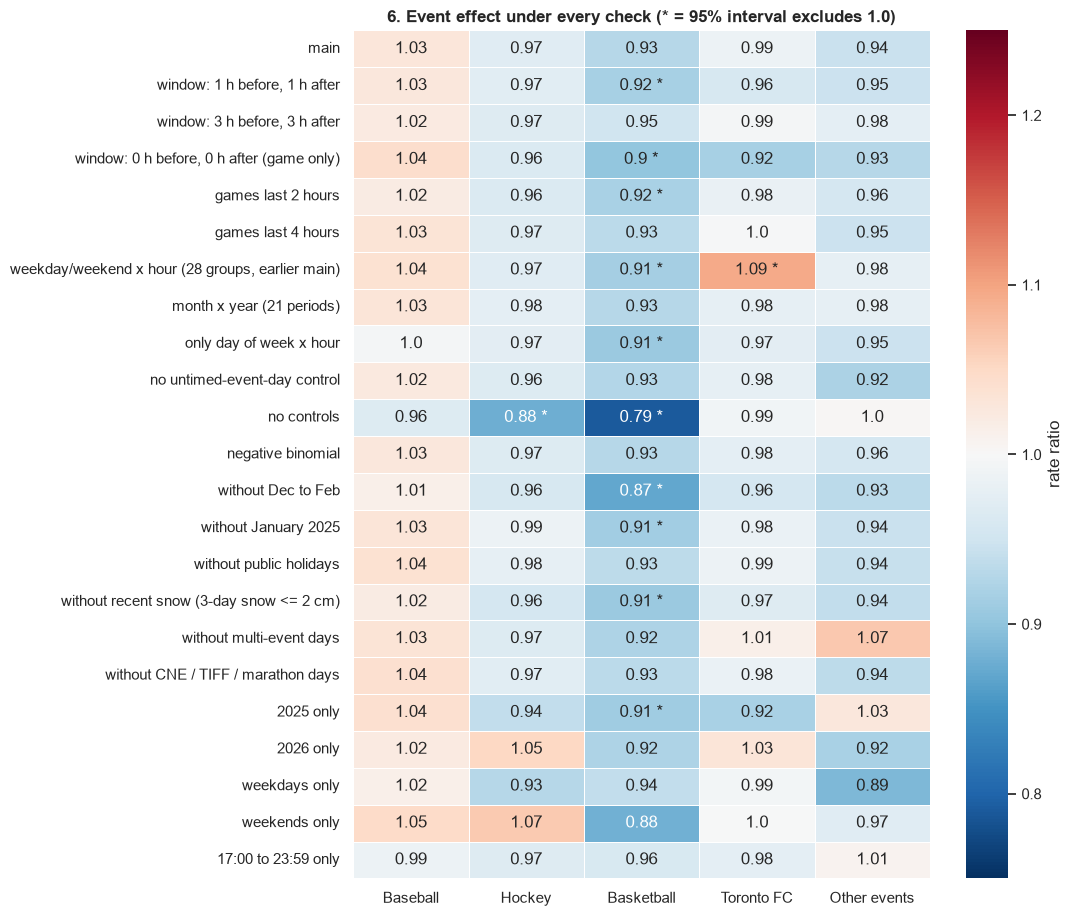

In [9]:
check_order = ["main"] + list(window_variants) + model_names[1:] + list(subsets)
summary_ratio = pd.DataFrame({name: RESULTS[name]["rate_ratio"] for name in check_order}).T
summary_clear = pd.DataFrame({name: (RESULTS[name]["lo"] > 1) | (RESULTS[name]["hi"] < 1) for name in check_order}).T
fig, ax = plt.subplots(figsize=(11, 0.34 * len(check_order) + 1.5))
labels = summary_ratio.round(2).astype(str) + np.where(summary_clear, " *", "")
sns.heatmap(summary_ratio, annot=labels, fmt="", cmap="RdBu_r", center=1, vmin=0.75, vmax=1.25, linewidths=0.4, ax=ax, cbar_kws={"label": "rate ratio"})
ax.set(title="6. Event effect under every check (* = 95% interval excludes 1.0)", ylabel="")
plt.tight_layout()
scorecard = pd.DataFrame({
    "lowest": summary_ratio.min(), "highest": summary_ratio.max(), "main": main_effects["rate_ratio"],
    "checks with interval excluding 1": summary_clear.sum(), "checks in total": len(check_order),
})
scorecard.round(3)

**How to read it:** all 23 checks in one picture. Rows are checks and columns are event types. A star means the 95% interval excludes 1.0. The table counts them.

**What stands out:**

| Event type | Lowest | Highest | Checks with interval excluding 1 (of 23) |
|---|---|---|---|
| Baseball | 0.97 | 1.05 | 0 |
| Hockey | 0.88 | 1.07 | 1 |
| **Basketball** | **0.79** | **0.96** | **10** |
| Toronto FC | 0.92 | 1.10 | 1 |
| Other events | 0.89 | 1.07 | 0 |

- **Basketball is below 1 in all 23 checks**, never above 0.96, and clear in 10. The main model itself (0.93, 0.86 to 1.01) is not clear.
- **Baseball and other events are never clear.**
- **Hockey's one clear case** is the no-controls model (0.88); the same event type is above 1 in 2026 and on weekends.
- **Toronto FC's one clear case** is the earlier weekday/weekend grouping (1.10), which the day of week × hour model removes. Without that case it ranges from 0.92 to 1.03.

### Verdict
- **Holds:** **no event type raises incidents.** Baseball (0.97 to 1.05) and other events (0.89 to 1.07) are never clearly different from 1 in 23 checks, hockey's one clear case is a decrease without controls, and it changes direction between checks.
- **Holds, but as a lead:** **basketball hours have fewer incidents**, about 7% (0.79 to 0.96 across all 23 checks, 10 clear). It is not a winter, window or model effect. But the main model is borderline (0.93, 0.86 to 1.01) and 6% of fake-event runs are as far from 1, so this is **suggestive, not solid**. Delay minutes, tested in notebook 03, are clearly lower for basketball (0.85, 0.77 to 0.93).
- **Does not hold:** **the Toronto FC rise (1.09 in the earlier version).** It disappears with day of week × hour (0.99), and fake events no longer give a rise.
- **Not tested here, but from notebook 03:** the near-venue rise for city events rests on 12 events and is only a lead (fake-event check 4.0% and 9.5%).

**Overall conclusion:** in 21 months of TTC data, major events in Toronto did not make bus service worse in the hours around them. If anything, basketball games at Scotiabank Arena have somewhat fewer incidents and less delay time than comparable hours, but this is borderline for incident counts.